In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'numpy', 'pandas', 'scipy', 'scikit-learn',
                       'matplotlib', 'threadpoolctl'])
print('Setup complete. Run the CSV upload cell next.')


Setup complete. Run the CSV upload cell next.


In [2]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()
csv_names = [name for name in uploaded if name.lower().endswith('.csv')]
if len(csv_names) != 1:
    raise ValueError('Upload exactly one CSV: South Dakota State_0466.csv. Rerun this cell to try again.')
SOURCE = Path(csv_names[0]).resolve()
print('Selected dataset:', SOURCE.name)


Saving South Dakota State_0466.csv to South Dakota State_0466.csv
Selected dataset: South Dakota State_0466.csv


# Exploring pitching styles in college softball
**Question 5. Can we identify different pitching styles based on velocity, spin rate, and ball movement?**

This project uses the supplied South Dakota State game file. It develops two complementary analyses: **pitch-level patterns** with an 80% training / 20% test split, and **pitcher-level profiles** that address the wording of the question directly. Six pitchers cannot establish a general taxonomy of pitching styles. The findings are exploratory, specific to this game, and do not measure pitching effectiveness.

Read the explanations, run each cell in order, and compare the printed results with the graphs. Run the cells to generate fresh outputs in Colab. The reference findings below describe the original analysis of the supplied CSV.

## 1. Set up the analysis
The setup and upload cells above prepare this Google Colab session. Run the remaining cells in order. All outputs go into `results/`, and graphs appear inline. Random seeds make the example reproducible; package versions are recorded in the final step.

Pandas handles tables, scikit-learn provides preprocessing and models, SciPy constructs the hierarchy, and Matplotlib draws the graphs. PCA compresses the feature space for visualization; it is not a clustering algorithm.

In [3]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances_argmin
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

BASE = Path.cwd()
# SOURCE was set by the Colab upload cell above.
RESULTS = BASE / 'results'
RESULTS.mkdir(exist_ok=True)
FEATURES = ['RelSpeed', 'SpinRate', 'HorzBreak', 'InducedVertBreak']
SEED = 42
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})
def figure(name):
    path = RESULTS / (name + '.png')
    plt.savefig(path, dpi=150)
    plt.show()
    plt.close()
    print('Graph:', path.name)
def show_table(frame):
    print(frame.to_string())
def sil(x, labels):
    return float(silhouette_score(x, labels)) if 1 < len(np.unique(labels)) < len(labels) else float('nan')
raw = pd.read_csv(SOURCE)
required = set(FEATURES + ['Pitcher', 'PitcherTeam', 'PitcherThrows', 'PitchUUID', 'TaggedPitchType', 'Date'])
missing = required - set(raw.columns)
if missing:
    raise ValueError(f'This CSV is missing required columns: {sorted(missing)}. Upload the original South Dakota State file.')
print('Raw shape:', raw.shape)
print('Dates:', raw['Date'].value_counts(dropna=False).to_dict())
print('Teams:', raw['PitcherTeam'].value_counts(dropna=False).to_dict())
print('Pitchers:', raw['Pitcher'].nunique())

Raw shape: (259, 125)
Dates: {'3/14/2026': 259}
Teams: {'South dakota state [sou03:2025]': 131, 'Uta fall 25': 128}
Pitchers: 6


## 2. Audit and clean without inventing measurements
Keep the original CSV unchanged. Strip extra spaces from text, standardize the inconsistent `RIse` pitch label, convert the four selected features to numbers, and treat infinite values as missing. These changes make joins and summaries consistent. Do not remove repeated pitches merely because their measurements are similar: separate pitches can legitimately resemble each other.

Remove exact duplicate rows if present. Repeated nonmissing pitch UUIDs would require investigation rather than automatic deletion. Empty columns are excluded from the cleaned table. No blanket outlier deletion is used: extreme observations might be legitimate pitch types or tracking problems. Without verified measurement definitions, a generic threshold would be arbitrary.

Both teams are included. A study exclusively about UTA would need a team filter **before** splitting and fitting, followed by a new analysis. The date field is used as recorded; team labels containing “Fall 25” are not treated as collection dates.

Exact duplicate rows removed: 0
Empty columns excluded: 12 ['PitcherSet', 'AutoPitchType', 'Notes', 'LastTrackedDistance', 'Stadium', 'Level', 'League', 'yt_FSRI', 'yt_SessionName', 'Note', 'yt_SeamLat', 'yt_SeamLong']
Numeric conversion failures: {'RelSpeed': 0, 'SpinRate': 0, 'HorzBreak': 0, 'InducedVertBreak': 0}
                  missing  percent_missing
RelSpeed               20             7.72
SpinRate               23             8.88
HorzBreak              23             8.88
InducedVertBreak       23             8.88
       RelSpeed  SpinRate  HorzBreak  InducedVertBreak
count   239.000   236.000    236.000           236.000
mean     64.467  1170.547     -1.168            -3.048
std       4.873   207.527      2.825             3.846
min      47.598   649.594     -6.784           -10.033
25%      62.028  1030.152     -3.271            -6.343
50%      66.331  1132.685     -1.600            -3.775
75%      67.994  1250.953      0.608            -0.439
max      71.202  1724.614  

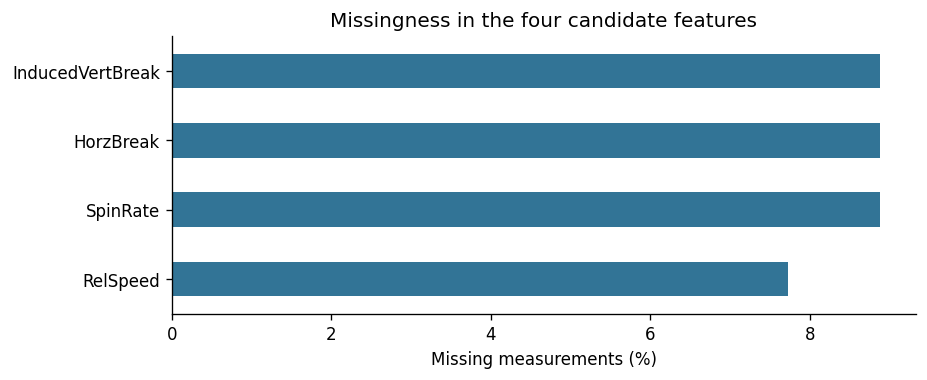

Graph: 01_missingness.png


In [4]:
data = raw.copy()
exact_duplicates = int(data.duplicated().sum())
data = data.drop_duplicates().copy()
data.insert(0, 'source_row', data.index + 2)  # CSV line number including header
for c in data.select_dtypes(include=['object', 'string']).columns:
    data[c] = data[c].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    data[c] = data[c].replace('', pd.NA)
data['TaggedPitchType'] = data['TaggedPitchType'].replace({'RIse': 'Rise'})
conversion_failures = {}
for c in FEATURES:
    before = data[c].notna()
    data[c] = pd.to_numeric(data[c], errors='coerce').replace([np.inf, -np.inf], np.nan)
    conversion_failures[c] = int((before & data[c].isna()).sum())
empty_columns = data.columns[data.isna().all()].tolist()
data = data.drop(columns=empty_columns)
uuid_duplicates = int(data.loc[data['PitchUUID'].notna(), 'PitchUUID'].duplicated().sum())
assert uuid_duplicates == 0, 'Investigate repeated pitch UUIDs before continuing.'
audit = pd.DataFrame({'missing': data[FEATURES].isna().sum(),
                      'percent_missing': data[FEATURES].isna().mean().mul(100).round(2)})
print('Exact duplicate rows removed:', exact_duplicates)
print('Empty columns excluded:', len(empty_columns), empty_columns)
print('Numeric conversion failures:', conversion_failures)
show_table(audit)
show_table(data[FEATURES].describe().round(3))
print('Pitcher handedness:')
show_table(data.groupby('Pitcher')['PitcherThrows'].first().to_frame())
data.to_csv(RESULTS/'cleaned_all_pitches.csv', index=False)
audit.to_csv(RESULTS/'feature_missingness.csv')
data.groupby('Pitcher')[FEATURES].agg(lambda s: s.isna().sum()).to_csv(RESULTS/'missingness_by_pitcher.csv')
ax = audit['percent_missing'].plot.barh(color='#327496', figsize=(8,3))
ax.set(xlabel='Missing measurements (%)', title='Missingness in the four candidate features')
figure('01_missingness')

### Reference findings from the original run
The audit found 20 missing release-velocity measurements and 23 missing values in each of spin rate, horizontal movement, and induced vertical movement. No exact duplicate rows were removed. The primary analysis needs all four measurements, so its eligible sample is 236 pitches, rather than 259. The missingness graph shows why treating blank tracking values as zero would distort the profiles.

## 3. Choose features to match the question
Use `RelSpeed` for release velocity, `SpinRate` for spin, `HorzBreak` for horizontal movement, and `InducedVertBreak` for induced vertical movement. The last feature is an alternative to total vertical break and may help separate movement from flight-time effects. Its exact physical convention must be verified with the export provider. The CSV contains no unit dictionary; graphs and tables therefore use the **recorded scale**, without asserting mph, rpm, inches, or feet.



## 4. Create the 80/20 split before fitting transformations
The user-selected split is 80% training, 20% testing. Split raw cleaned rows first and stratify by pitcher so all six pitchers contribute to both portions. The split is at the **pitch level**, not the pitcher level. It assesses new pitches from the same observed pitchers, not new athletes or games. Related pitches can still be highly dependent, so the test set is a modest within-game check.

For the main clustering analysis, drop rows with any missing core feature separately within each split. This avoids making up movement or spin values and yields a transparent complete-case baseline. Report the resulting counts, which can differ slightly from 80/20. Compare median imputation later using training data only. Keep rows with missing outcomes because outcomes are not needed for this question.

`StandardScaler` learns training means and standard deviations; each feature then has comparable numerical influence. Apply the **same** transformation to test data. Calling `fit_transform` on the test set would change the coordinate system and leak information.

Before complete-case exclusion: training = 207 testing = 52
After complete-case exclusion: training = 191 testing = 45
Excluded for missing features: 16 train; 7 test
partition       test  train
Pitcher                    
Bella Macmahon     2      6
Grace Proctor     11     43
Keira Carrillo     4     14
Kynlee Bowlin      9     37
Maddie Furniss    16     66
Tayler Baker      10     41
                  RelSpeed  SpinRate  HorzBreak  InducedVertBreak
RelSpeed             1.000    -0.089      0.218            -0.474
SpinRate            -0.089     1.000     -0.384             0.641
HorzBreak            0.218    -0.384      1.000            -0.339
InducedVertBreak    -0.474     0.641     -0.339             1.000


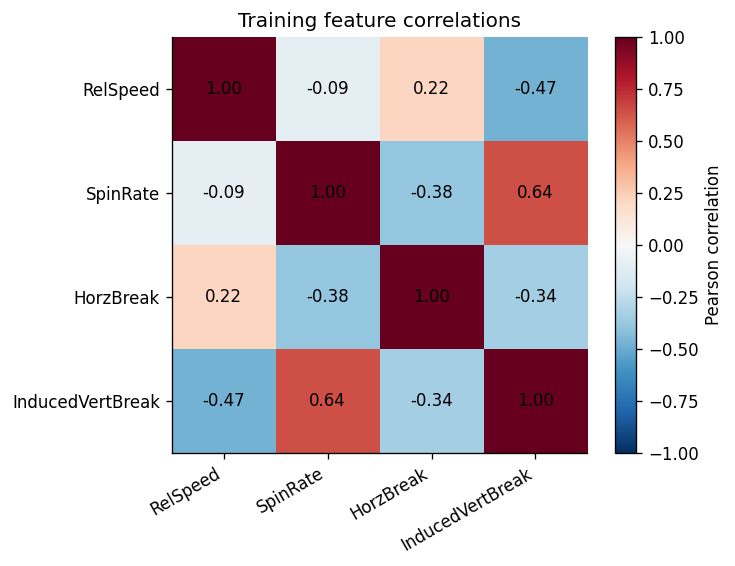

Graph: 02_training_correlations.png


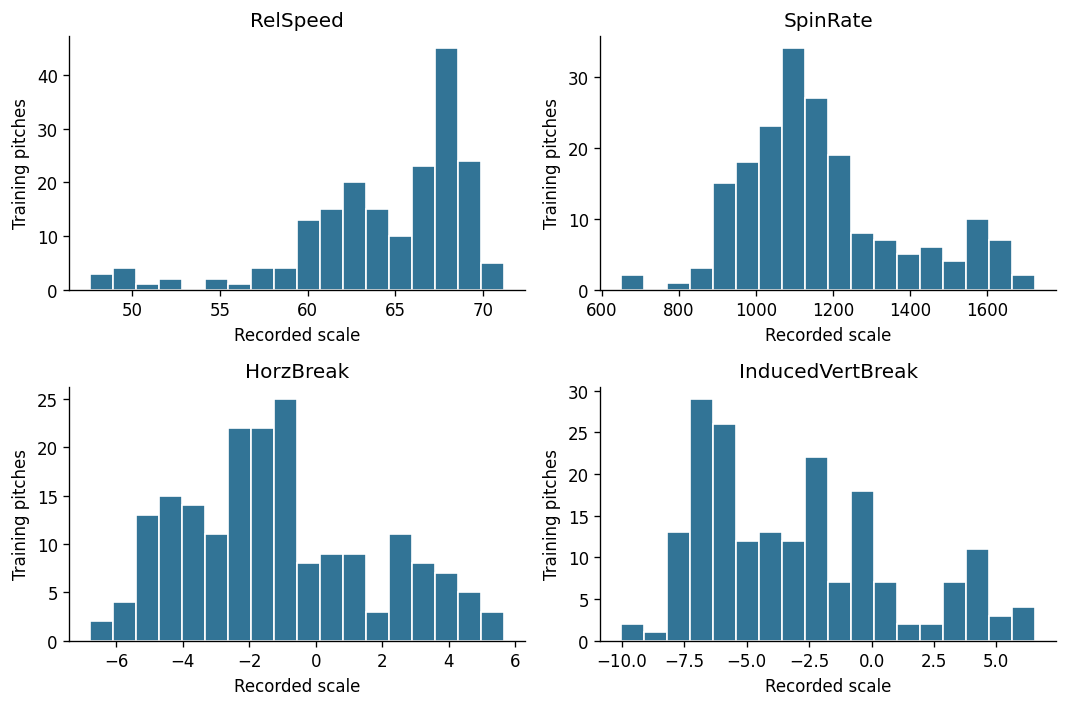

Graph: 03_training_distributions.png


In [5]:
train_raw, test_raw = train_test_split(data, test_size=0.20, random_state=SEED,
                                       stratify=data['Pitcher'])
train = train_raw.dropna(subset=FEATURES).copy()
test = test_raw.dropna(subset=FEATURES).copy()
assert set(train_raw.source_row).isdisjoint(test_raw.source_row)
assert len(train_raw) + len(test_raw) == len(data)
scaler = StandardScaler()
X_train = scaler.fit_transform(train[FEATURES])
X_test = scaler.transform(test[FEATURES])
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
print('Before complete-case exclusion: training =', len(train_raw), 'testing =', len(test_raw))
print('After complete-case exclusion: training =', len(train), 'testing =', len(test))
print('Excluded for missing features:', len(train_raw)-len(train), 'train;', len(test_raw)-len(test), 'test')
split = data[['source_row','Pitcher']].copy()
split['partition'] = np.where(split.source_row.isin(train_raw.source_row), 'train', 'test')
split['complete_core_features'] = data[FEATURES].notna().all(axis=1)
split.to_csv(RESULTS/'split_manifest.csv', index=False)
show_table(pd.crosstab(split.Pitcher, split.partition))
correlation = train[FEATURES].corr()
show_table(correlation.round(3))
fig, ax = plt.subplots(figsize=(6,4.5))
im=ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(4), FEATURES, rotation=30, ha='right'); ax.set_yticks(range(4), FEATURES)
for i in range(4):
    for j in range(4): ax.text(j,i,f'{correlation.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im, ax=ax, label='Pearson correlation'); ax.set_title('Training feature correlations')
figure('02_training_correlations')
fig, axes = plt.subplots(2,2,figsize=(9,6))
for ax, c in zip(axes.flat, FEATURES):
    ax.hist(train[c], bins=18, color='#327496', edgecolor='white')
    ax.set(title=c, xlabel='Recorded scale', ylabel='Training pitches')
fig.tight_layout(); figure('03_training_distributions')

### Reference findings from the original run
The split has 207 training and 52 test rows before exclusions, and 191 training and 45 test rows afterward. Across the full file, 23 rows lack at least one core measurement. Keep these distinctions in the report: 80/20 refers to the initial split, while model metrics use the complete-case subsets. Feature distributions and correlations describe the training data only.

## 5. Fit K-means and select the number of groups using training data
K-means minimizes squared distance to cluster centers in the standardized four-feature space. It favors compact groups and can be influenced by outliers. `n_init=30` uses multiple initializations; `random_state` makes them reproducible. Cluster numbers are arbitrary identifiers, not rankings of pitcher quality.

Try 2 through 6 groups and select the largest **training silhouette score**. Silhouette compares a point's similarity to its own group versus other groups; it ranges from -1 to 1. A higher value indicates better separation for this representation. It does not prove that a true style taxonomy exists. Inertia decreases as groups are added, so its elbow is supporting context rather than a standalone rule. Do not use test results to choose k.

   k  train_silhouette  train_inertia  smallest_train_cluster
0  2            0.5201       432.1261                      33
1  3            0.3766       320.6042                      33
2  4            0.4325       219.2788                      16
3  5            0.4281       172.8993                      16
4  6            0.4565       139.8031                      16
Selected k: 2


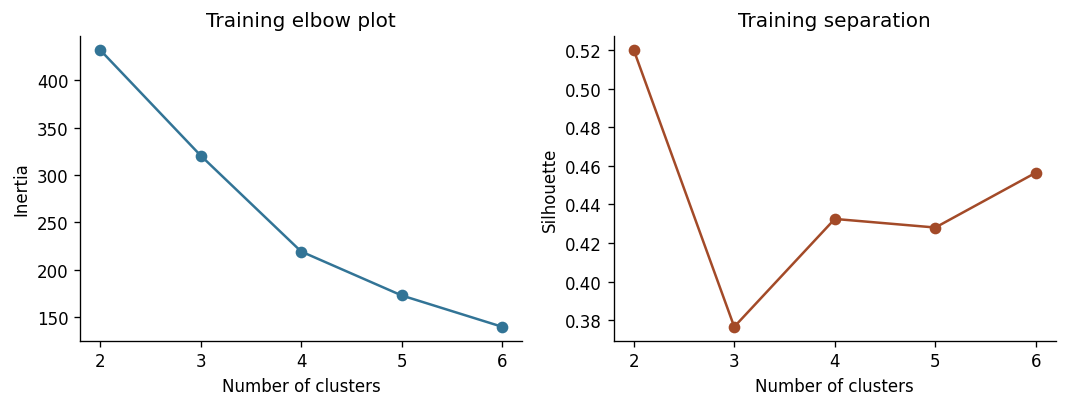

Graph: 04_choose_k.png
         RelSpeed  SpinRate  HorzBreak  InducedVertBreak  training_pitches
cluster                                                                   
0          65.810  1108.099     -0.388            -4.336               158
1          57.743  1466.946     -4.944             3.500                33


In [6]:
candidates=[]
models={}
for k in range(2,7):
    model=KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(X_train)
    models[k]=model
    candidates.append({'k':k, 'train_silhouette':sil(X_train, model.labels_),
                       'train_inertia':float(model.inertia_),
                       'smallest_train_cluster':int(np.bincount(model.labels_).min())})
selection=pd.DataFrame(candidates)
best_k=int(selection.loc[selection.train_silhouette.idxmax(),'k'])
km=models[best_k]
train_labels=km.labels_
selection.to_csv(RESULTS/'k_selection_training.csv', index=False)
show_table(selection.round(4)); print('Selected k:',best_k)
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
axes[0].plot(selection.k,selection.train_inertia,'o-',color='#327496')
axes[0].set(xlabel='Number of clusters',ylabel='Inertia',title='Training elbow plot')
axes[1].plot(selection.k,selection.train_silhouette,'o-',color='#a34a28')
axes[1].set(xlabel='Number of clusters',ylabel='Silhouette',title='Training separation')
fig.tight_layout();figure('04_choose_k')
centers=pd.DataFrame(scaler.inverse_transform(km.cluster_centers_),columns=FEATURES)
centers.index.name='cluster'
centers['training_pitches']=np.bincount(train_labels,minlength=best_k)
centers.to_csv(RESULTS/'training_cluster_centers.csv')
show_table(centers.round(3))

### Reference findings from the original run
For this run, k=2 has the highest training silhouette (0.520), compared with 0.377 for k=3 and 0.456 for k=6. The two training centers differ substantially: cluster 0 has mean recorded velocity 65.81 and spin 1108.10, whereas cluster 1 has mean velocity 57.74 and spin 1466.95. Their induced vertical movement means are -4.34 and +3.50 in the recorded scale. These are relative descriptions, not labels of pitch quality. Adding groups reduces inertia but does not improve silhouette over k=2.

## 6. Compare hierarchical clustering and assess training stability
Ward hierarchical clustering starts with separate points and progressively merges groups to minimize the increase in within-group variance. The dendrogram shows those merges; the vertical axis is Ward linkage distance in standardized space. The displayed pitch dendrogram is truncated for readability. Cut the hierarchy at the same k as K-means to compare methods without tuning another model on the test set.

Adjusted Rand index (ARI) measures agreement between two partitions while ignoring label numbering; 1 means identical partitions and values near 0 indicate chance-level agreement. This is **method agreement**, not accuracy against true styles. Refitting K-means on 20 training bootstrap samples and assigning the original training points measures sensitivity to resampling. It is a diagnostic rather than a confidence interval, and resampling pitches ignores within-pitcher dependence.

Training Ward silhouette: 0.4861
Training K-means / Ward ARI: 0.813


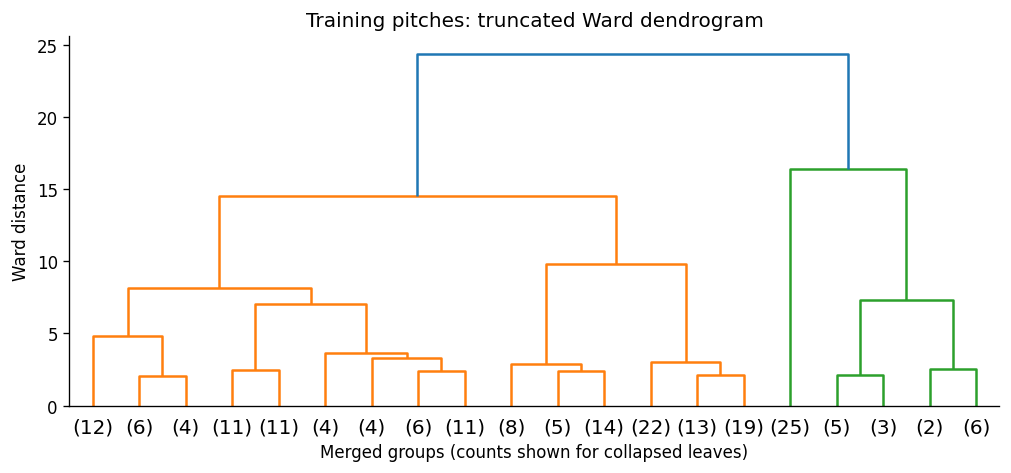

Graph: 05_pitch_dendrogram.png
Bootstrap ARI median/min/max: 1.0 1.0 1.0


In [7]:
Z=linkage(X_train,method='ward')
hier_labels=cut_tree(Z,n_clusters=best_k).ravel()
method_ari=float(adjusted_rand_score(train_labels,hier_labels))
hier_sil=sil(X_train,hier_labels)
hier_centers=np.vstack([X_train[hier_labels==c].mean(axis=0) for c in range(best_k)])
print('Training Ward silhouette:',round(hier_sil,4))
print('Training K-means / Ward ARI:',round(method_ari,4))
plt.figure(figsize=(10,4));dendrogram(Z,truncate_mode='lastp',p=20,show_leaf_counts=True)
plt.title('Training pitches: truncated Ward dendrogram')
plt.xlabel('Merged groups (counts shown for collapsed leaves)');plt.ylabel('Ward distance')
figure('05_pitch_dendrogram')
rng=np.random.default_rng(SEED)
bootstrap_ari=[]
for b in range(20):
    idx=rng.integers(0,len(X_train),len(X_train))
    refit=KMeans(n_clusters=best_k,n_init=20,random_state=SEED+b).fit(X_train[idx])
    bootstrap_ari.append(adjusted_rand_score(train_labels,refit.predict(X_train)))
print('Bootstrap ARI median/min/max:',*[round(float(v),4) for v in
      [np.median(bootstrap_ari),np.min(bootstrap_ari),np.max(bootstrap_ari)]])
pd.DataFrame({'bootstrap':range(20),'ARI':bootstrap_ari}).to_csv(RESULTS/'training_stability.csv',index=False)

### Reference findings from the original run
Ward and K-means agree substantially on training assignments (ARI 0.813). The bootstrap median ARI is 1.000, with a range of 1.000 to 1.000. This indicates a reproducible partition under these pitch-level perturbations, while leaving the same-game and same-pitcher limitations unresolved.

## 7. Fit PCA on training data for visualization
PCA finds orthogonal directions that explain variation in the scaled features. Fit it on training data and transform test data using the learned components. Keep all four original standardized features for clustering; the first two principal components are only a visual summary. Points that overlap in two dimensions may still differ in the full space.

The explained-variance proportions describe how much variation the components preserve. Component coefficients indicate which measurements contribute to each axis; they are not supervised feature importance. PCA axis signs can reverse without changing the geometry.

In [8]:
pca=PCA().fit(X_train)
PC_train=pca.transform(X_train)
PC_test=pca.transform(X_test)
pca_table=pd.DataFrame({'component':['PC1','PC2','PC3','PC4'],
                        'explained_variance_ratio':pca.explained_variance_ratio_,
                        'cumulative_variance':np.cumsum(pca.explained_variance_ratio_)})
show_table(pca_table.round(4))
coefficients=pd.DataFrame(pca.components_.T,index=FEATURES,columns=pca_table.component)
show_table(coefficients.round(4))
pca_table.to_csv(RESULTS/'pca_variance.csv',index=False)
coefficients.to_csv(RESULTS/'pca_component_coefficients.csv')

  component  explained_variance_ratio  cumulative_variance
0       PC1                    0.5285               0.5285
1       PC2                    0.2326               0.7612
2       PC3                    0.1794               0.9405
3       PC4                    0.0595               1.0000
component            PC1     PC2     PC3     PC4
RelSpeed         -0.3877  0.8303  0.0730  0.3937
SpinRate          0.5331  0.4988  0.3436 -0.5907
HorzBreak        -0.4442 -0.2354  0.8586 -0.1002
InducedVertBreak  0.6068 -0.0800  0.3733  0.6972


### Reference findings from the original run
PC1 preserves 52.9% and PC2 preserves 23.3% of training variation, totaling 76.1%. In the printed coefficient table, PC1 combines positive spin and induced vertical movement with negative velocity and horizontal movement. PC2 is dominated by velocity. The signs describe this fitted coordinate system and should not be interpreted as causal relationships.

## 8. Use the holdout once, with frozen training models
K-means assigns a test pitch to its nearest learned center. Report test silhouette and mean squared distance to the assigned training center. Squared distance is the sum across the four standardized features, averaged across pitches; lower values mean a tighter fit to those centers, not better softball performance. Compare training and test values cautiously because the holdout is small.

Ward clustering has no native `predict` rule. For an explicitly labeled extension, assign test observations to the nearest **training Ward-cluster mean**. This rule does not rebuild the hierarchy and is not equivalent to adding the pitches and reclustering. Report its agreement with the K-means assignments as a secondary comparison. No classification accuracy, precision, or recall is appropriate without independently established style labels.

{
  "selected_k": 2,
  "raw_train_rows": 207,
  "raw_test_rows": 52,
  "complete_train_rows": 191,
  "complete_test_rows": 45,
  "train_silhouette": 0.5200607161460452,
  "test_silhouette": 0.5107554832121838,
  "train_mean_squared_distance": 2.2624405552481726,
  "test_mean_squared_distance": 1.927459382860826,
  "ward_train_silhouette": 0.486056078328914,
  "train_method_ARI": 0.8130165939336758,
  "test_method_ARI": 1.0,
  "bootstrap_ARI_median": 1.0,
  "PCA_first_two_variance": 0.7611624091233224
}
Test cluster counts: {np.int32(0): np.int64(38), np.int32(1): np.int64(7)}


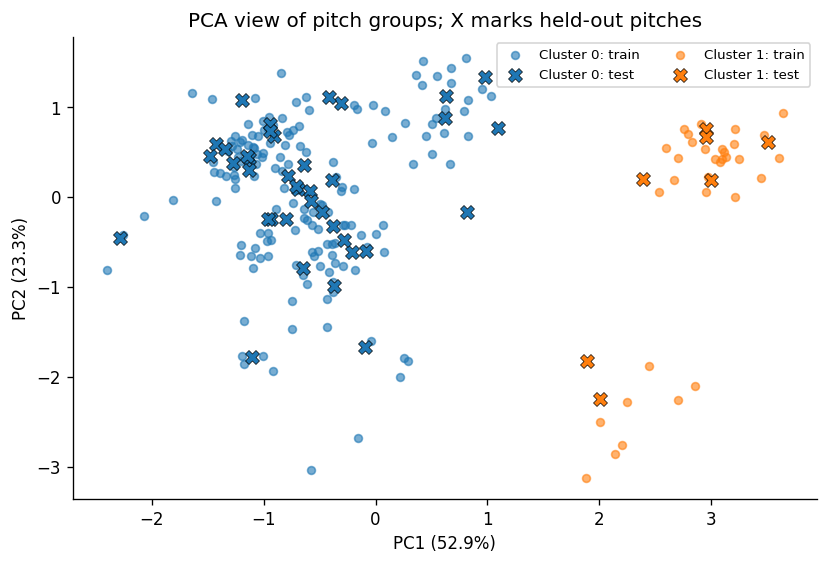

Graph: 06_pitch_pca.png
kmeans_cluster      0      1
Pitcher                     
Bella Macmahon  100.0    0.0
Grace Proctor   100.0    0.0
Keira Carrillo  100.0    0.0
Kynlee Bowlin     0.0  100.0
Maddie Furniss  100.0    0.0
Tayler Baker    100.0    0.0


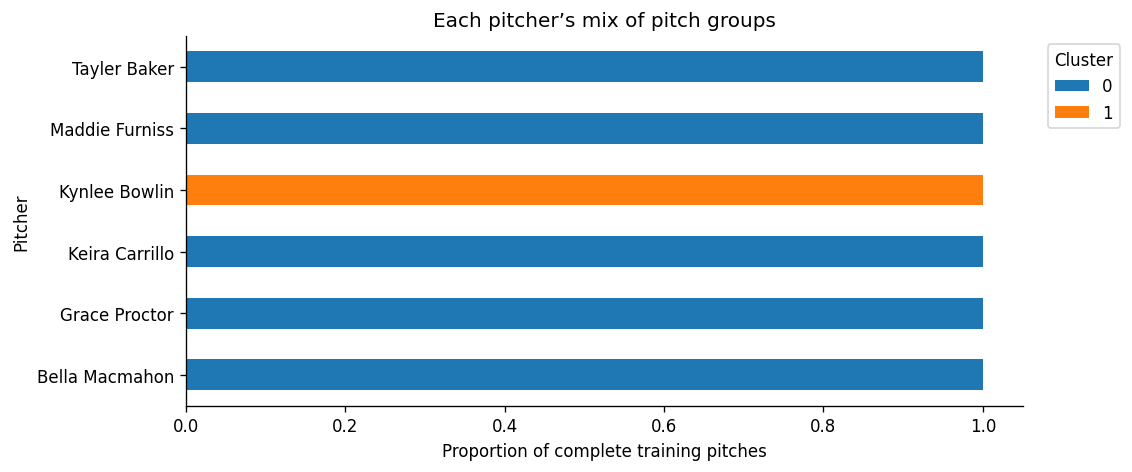

Graph: 07_pitcher_group_mix.png
Training handedness by cluster:
kmeans_cluster    0   1
PitcherThrows          
Left             42   0
Right           116  33
Training pitch labels by cluster (not used to fit):
kmeans_cluster     0   1
TaggedPitchType         
Change             0   8
Curve             28   1
Fast               0   2
Rise              21   3
Screw              7  19
Unlabeled        102   0


In [9]:
test_labels=km.predict(X_test)
hier_test=pairwise_distances_argmin(X_test,hier_centers)
train_msd=float(np.mean(np.sum((X_train-km.cluster_centers_[train_labels])**2,axis=1)))
test_msd=float(np.mean(np.sum((X_test-km.cluster_centers_[test_labels])**2,axis=1)))
metrics={'selected_k':best_k,'raw_train_rows':len(train_raw),'raw_test_rows':len(test_raw),
         'complete_train_rows':len(train),'complete_test_rows':len(test),
         'train_silhouette':sil(X_train,train_labels),'test_silhouette':sil(X_test,test_labels),
         'train_mean_squared_distance':train_msd,'test_mean_squared_distance':test_msd,
         'ward_train_silhouette':hier_sil,'train_method_ARI':method_ari,
         'test_method_ARI':float(adjusted_rand_score(test_labels,hier_test)),
         'bootstrap_ARI_median':float(np.median(bootstrap_ari)),
         'PCA_first_two_variance':float(pca.explained_variance_ratio_[:2].sum())}
print(json.dumps(metrics,indent=2))
print('Test cluster counts:',dict(zip(*np.unique(test_labels,return_counts=True))))
train['partition']='train';test['partition']='test'
train['kmeans_cluster']=train_labels;test['kmeans_cluster']=test_labels
train['ward_cluster_or_nearest_mean']=hier_labels
test['ward_cluster_or_nearest_mean']=hier_test
assigned=pd.concat([train,test]).sort_values('source_row')
assigned.to_csv(RESULTS/'complete_case_pitch_assignments.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for c in range(best_k):
    color=plt.get_cmap('tab10')(c)
    ax.scatter(PC_train[train_labels==c,0],PC_train[train_labels==c,1],color=color,s=22,alpha=.6,label=f'Cluster {c}: train')
    ax.scatter(PC_test[test_labels==c,0],PC_test[test_labels==c,1],color=color,marker='X',s=70,edgecolor='black',linewidth=.4,label=f'Cluster {c}: test')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',title='PCA view of pitch groups; X marks held-out pitches')
ax.legend(fontsize=8,ncol=2);figure('06_pitch_pca')
composition=pd.crosstab(train.Pitcher,train.kmeans_cluster,normalize='index').reindex(columns=range(best_k),fill_value=0)
show_table((composition*100).round(1))
composition.plot.barh(stacked=True,figsize=(9,4),color=[plt.get_cmap('tab10')(c) for c in range(best_k)])
plt.xlabel('Proportion of complete training pitches');plt.title('Each pitcher’s mix of pitch groups')
plt.legend(title='Cluster',bbox_to_anchor=(1.02,1));figure('07_pitcher_group_mix')
composition.to_csv(RESULTS/'training_pitcher_cluster_proportions.csv')
print('Training handedness by cluster:');show_table(pd.crosstab(train.PitcherThrows,train.kmeans_cluster))
print('Training pitch labels by cluster (not used to fit):')
show_table(pd.crosstab(train.TaggedPitchType.fillna('Unlabeled'),train.kmeans_cluster))

### Reference findings from the original run
The PCA graph shows separated groups along PC1; held-out X markers largely occupy the same regions as training points. Test silhouette is 0.511 versus 0.520 for training. The pitcher-composition graph is more revealing: all 33 complete training pitches from Kynlee Bowlin are in cluster 1, while all 158 complete training pitches from the other five pitchers are in cluster 0. Thus the dominant partition distinguishes one pitcher’s observed profile. It is not evidence for two general categories of pitching style. Because Bowlin and several other pitchers are right-handed, the baseline grouping is not simply left-handed versus right-handed pitching.

## 9. Address pitching styles directly with pitcher-level profiles
Aggregate the **complete training pitches** into one mean profile per pitcher, keeping each pitcher equally weighted in this comparison. Fit a separate scaler to these six profiles: this is a new descriptive analysis, not the pitch-level scaler reused at another unit. Pitcher means mix pitch types, so they describe the repertoire observed in this game and can hide within-pitcher variation. The cluster-proportion graph complements these averages.

Show the six-profile Ward dendrogram and a two-group K-means illustration. Two groups are fixed for a simple comparison, not declared optimal; with six observations, even high silhouette values are fragile. A profile based on a handful of pitches is less reliable than one based on many pitches. Inspect the training pitch counts and compare held-out means. We do **not** split six pitcher profiles 80/20 (which would leave only two pitchers for testing). We do not report pitcher-style accuracy.

                RelSpeed  SpinRate  HorzBreak  InducedVertBreak  training_pitches  illustrative_style_group throwing_hand
Pitcher                                                                                                                  
Bella Macmahon    64.302   906.309      1.462            -6.793                 6                         0         Right
Grace Proctor     62.642  1125.034      2.667            -3.659                42                         0          Left
Keira Carrillo    66.746  1062.272      0.929            -1.498                13                         0         Right
Kynlee Bowlin     57.743  1466.946     -4.944             3.500                33                         1         Right
Maddie Furniss    68.532  1082.388     -1.616            -6.540                57                         0         Right
Tayler Baker      65.177  1172.120     -2.551            -2.458                40                         0         Right
Illustrative six-profile

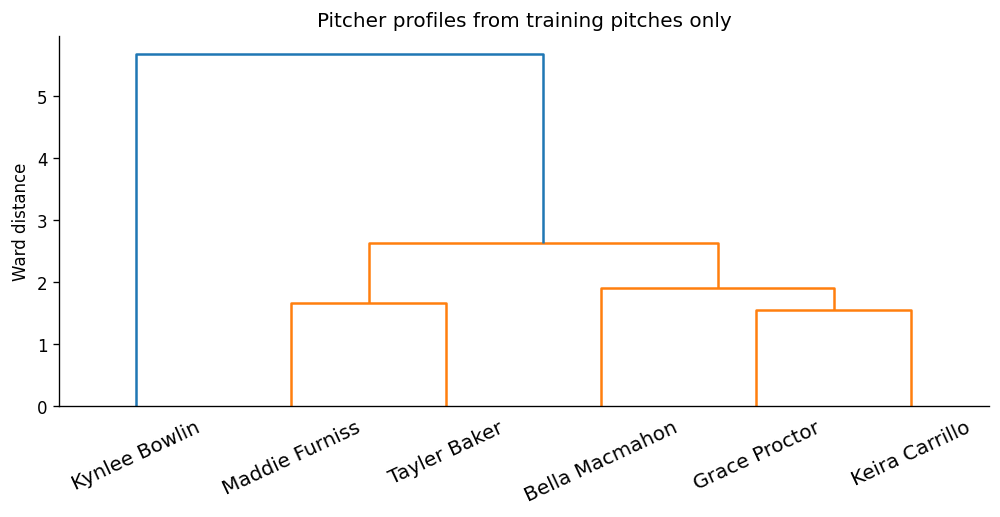

Graph: 08_pitcher_dendrogram.png


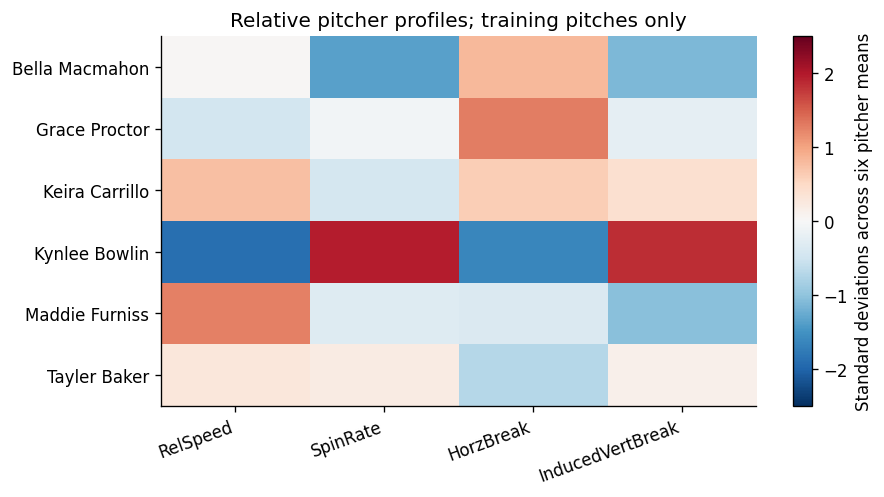

Graph: 09_pitcher_profiles.png
Held-out mean minus training mean, recorded scale:
                RelSpeed  SpinRate  HorzBreak  InducedVertBreak
Pitcher                                                        
Bella Macmahon     2.513     8.390      1.759            -1.105
Grace Proctor      0.019     7.969     -0.841            -0.735
Keira Carrillo    -0.306    70.309     -0.248             0.402
Kynlee Bowlin     -0.076     0.712      0.039            -1.287
Maddie Furniss    -0.021    19.302      0.223             0.092
Tayler Baker       0.219   -25.548      0.506             0.608


In [10]:
profiles=train.groupby('Pitcher')[FEATURES].mean()
profile_counts=train.groupby('Pitcher').size().rename('training_pitches')
heldout_profiles=test.groupby('Pitcher')[FEATURES].mean().reindex(profiles.index)
profile_scaler=StandardScaler()
Xp=profile_scaler.fit_transform(profiles)
profile_km=KMeans(n_clusters=2,n_init=30,random_state=SEED).fit(Xp)
profile_results=profiles.join(profile_counts)
profile_results['illustrative_style_group']=profile_km.labels_
profile_results['throwing_hand']=train.groupby('Pitcher').PitcherThrows.first()
show_table(profile_results.round(3))
profile_results.to_csv(RESULTS/'training_pitcher_profiles.csv')
heldout_profiles.to_csv(RESULTS/'heldout_pitcher_profiles.csv')
print('Illustrative six-profile silhouette:',round(sil(Xp,profile_km.labels_),4))
plt.figure(figsize=(10,4));dendrogram(linkage(Xp,method='ward'),labels=profiles.index.tolist(),leaf_rotation=25)
plt.ylabel('Ward distance');plt.title('Pitcher profiles from training pitches only')
figure('08_pitcher_dendrogram')
fig,ax=plt.subplots(figsize=(8,4))
im=ax.imshow(Xp,cmap='RdBu_r',vmin=-2.5,vmax=2.5,aspect='auto')
ax.set_xticks(range(4),FEATURES,rotation=20,ha='right');ax.set_yticks(range(len(profiles)),profiles.index)
fig.colorbar(im,ax=ax,label='Standard deviations across six pitcher means')
ax.set_title('Relative pitcher profiles; training pitches only');figure('09_pitcher_profiles')
profile_differences=(heldout_profiles-profiles)
print('Held-out mean minus training mean, recorded scale:')
show_table(profile_differences.round(3))
profile_differences.to_csv(RESULTS/'heldout_minus_train_pitcher_means.csv')

### Reference findings from the original run
The pitcher heatmap and dendrogram also place Bowlin apart from the others using the four training-profile means. Her observed training profile combines lower velocity, higher spin, negative horizontal movement, and positive induced vertical movement relative to most peers. Bella Macmahon contributes only six complete training pitches, versus 57 for Maddie Furniss, so their mean profiles have unequal precision. These profile groups are descriptive and the fixed two-group illustration is not an independently validated style model.

## 10. Check sensitivity using training observations only
The four-feature baseline is selected from the research question, not from the best-looking graph. These alternatives test assumptions rather than optimize test performance:

* **Median imputation** retains training rows with at least one observed core measurement and fills missing features using training medians. Entirely unmeasured rows are not turned into artificial “typical” pitches. Compare labels on the same complete training observations.
* **Robust scaling** uses training medians and interquartile ranges, reducing sensitivity to extremes without deleting them.
* **Absolute horizontal movement** removes direction to test sensitivity to handedness and coordinate signs, while recognizing the loss of information.
* **Velocity plus movement** omits spin rate to show whether including spin materially changes the groups. This is not a statistical feature-importance ranking.

Keep k fixed and compare ARI against the baseline on the same complete training rows. A low ARI means the grouping depends on that choice. Do not silently replace the main model with whichever alternative appears most favorable.

In [11]:
sensitivity=[]
for name,cols,transform in [
    ('Robust scaling',FEATURES,RobustScaler()),
    ('Absolute horizontal movement',FEATURES,StandardScaler()),
    ('Velocity plus movement',['RelSpeed','HorzBreak','InducedVertBreak'],StandardScaler())]:
    frame=train[cols].copy()
    if name=='Absolute horizontal movement': frame['HorzBreak']=frame.HorzBreak.abs()
    xx=transform.fit_transform(frame)
    alternative=KMeans(n_clusters=best_k,n_init=30,random_state=SEED).fit(xx)
    sensitivity.append({'choice':name,'train_rows':len(frame),'silhouette_in_own_space':sil(xx,alternative.labels_),
                        'ARI_vs_baseline':float(adjusted_rand_score(train_labels,alternative.labels_))})
impute_rows=train_raw.dropna(subset=FEATURES,how='all')
imputer=SimpleImputer(strategy='median')
imputed=imputer.fit_transform(impute_rows[FEATURES])
impute_scaler=StandardScaler().fit(imputed)
impute_x=impute_scaler.transform(imputed)
impute_model=KMeans(n_clusters=best_k,n_init=30,random_state=SEED).fit(impute_x)
common_x=impute_scaler.transform(imputer.transform(train[FEATURES]))
sensitivity.append({'choice':'Training median imputation','train_rows':len(impute_rows),
                    'silhouette_in_own_space':sil(impute_x,impute_model.labels_),
                    'ARI_vs_baseline':float(adjusted_rand_score(train_labels,impute_model.predict(common_x)))})
sensitivity=pd.DataFrame(sensitivity)
show_table(sensitivity.round(4));sensitivity.to_csv(RESULTS/'training_sensitivity.csv',index=False)

                         choice  train_rows  silhouette_in_own_space  ARI_vs_baseline
0                Robust scaling         191                   0.5193           1.0000
1  Absolute horizontal movement         191                   0.5054           0.8790
2        Velocity plus movement         191                   0.5212           0.8565
3    Training median imputation         193                   0.5204           1.0000


### Reference findings from the original run
Robust scaling and training-median imputation preserve the baseline assignments on the complete training rows (ARI 1.000). Absolute horizontal movement changes some memberships (ARI 0.879), as does omitting spin (ARI 0.856). The broad grouping is fairly persistent in these checks, but the details depend on the representation. Median imputation adds only two partially measured training rows; rows missing all four features remain excluded. Silhouettes from different transformed spaces should not be treated as directly comparable evidence for which physical representation is best.

## 11. Interpret the results and preserve reproducibility
Use the learned centers to describe the groups in relative terms, for example “higher velocity and lower spin than another group.” Do not name a group “riseball” or “elite” solely from these four measurements. The observed pitch labels are incomplete and were not independent ground truth. A silhouette score establishes geometric separation for the chosen features, not baseball/softball validity or causal effects.

The strongest answer this dataset supports is whether **different physical profiles are visible within this game**. Cluster composition, the pitcher heatmap, and the dendrogram can support a tentative comparison; they cannot establish stable styles across seasons. Check whether the groups mostly mirror pitcher identity or throwing hand. Larger, multi-game samples with verified units, consistent tracking, enough pitches per pitch type, and additional pitchers are needed for stronger conclusions. A future generalization study should hold out whole games or athletes rather than randomly dividing their pitches.

The summary below is calculated from this run, not inserted as a hypothetical result. All CSV tables and graphs are saved in `results/`; the raw file remains unchanged.

In [12]:
summary = f"""Question 5: Can we identify different pitching styles based on velocity, spin rate, and ball movement?

The file has {len(raw)} pitches, {raw.shape[1]} columns and {data.Pitcher.nunique()} pitchers.
The 80/20 pitch split produced {len(train_raw)} training and {len(test_raw)} test rows before missing-feature exclusions.
The complete-case analysis used {len(train)} training pitches and {len(test)} test pitches.
Training silhouette selected k={best_k} among k=2..6.
K-means silhouette: training {metrics['train_silhouette']:.3f}; test {metrics['test_silhouette']:.3f}.
Mean squared standardized distance to training centers: train {train_msd:.3f}; test {test_msd:.3f}.
Ward versus K-means training ARI: {method_ari:.3f}.
Bootstrap median ARI: {metrics['bootstrap_ARI_median']:.3f}.
The first two PCA components preserve {metrics['PCA_first_two_variance']:.1%} of training variation.

These results describe pitch groups and six exploratory pitcher profiles within one game.
They do not establish stable population-level pitching styles or identify superior pitchers.
Signed movement, pitcher identity, missing tracking, unequal pitch counts and repertoire mix limit interpretation.
"""
print(summary)
(RESULTS/'summary.txt').write_text(summary,encoding='utf-8')
(RESULTS/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'scipy':scipy.__version__,'scikit-learn':sklearn.__version__,'matplotlib':matplotlib.__version__}
print('Versions:',versions)
(RESULTS/'versions.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')
assert sum(np.bincount(train_labels))==len(train)
assert sum(np.bincount(test_labels,minlength=best_k))==len(test)
assert len(assigned)==len(train)+len(test)
assert np.allclose(scaler.mean_,train[FEATURES].mean().values)
assert assigned.source_row.is_unique
print('Verification passed: partitions disjoint, counts reconcile, finite features, training-only scale parameters.')

Question 5: Can we identify different pitching styles based on velocity, spin rate, and ball movement?

The file has 259 pitches, 125 columns and 6 pitchers.
The 80/20 pitch split produced 207 training and 52 test rows before missing-feature exclusions.
The complete-case analysis used 191 training pitches and 45 test pitches.
Training silhouette selected k=2 among k=2..6.
K-means silhouette: training 0.520; test 0.511.
Mean squared standardized distance to training centers: train 2.262; test 1.927.
Ward versus K-means training ARI: 0.813.
Bootstrap median ARI: 1.000.
The first two PCA components preserve 76.1% of training variation.

These results describe pitch groups and six exploratory pitcher profiles within one game.
They do not establish stable population-level pitching styles or identify superior pitchers.
Signed movement, pitcher identity, missing tracking, unequal pitch counts and repertoire mix limit interpretation.

Versions: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas':

In [13]:
import shutil
from google.colab import files

archive = shutil.make_archive(str(BASE / 'Softball_Pitching_Styles_Colab_Results'),
                              'zip', root_dir=RESULTS)
print('Downloading:', Path(archive).name)
files.download(archive)


Downloading: Softball_Pitching_Styles_Colab_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>